In [ ]:
!pip install -q huggingface_hub

In [ ]:
from huggingface_hub import HfApi

api = HfApi()

dataset_info = api.dataset_info("Tamer-Saleh/S1GFloods")

print("Dataset:", dataset_info.id)
print("Files:")
for file in dataset_info.siblings:
    print(file.rfilename)

Dataset: Tamer-Saleh/S1GFloods
Files:
.gitattributes
README.md
S1GFloods.rar


In [ ]:
from huggingface_hub import hf_hub_download

readme_path = hf_hub_download(
    repo_id="Tamer-Saleh/S1GFloods",
    filename="README.md",
    repo_type="dataset"
)

with open(readme_path, "r") as file:
    print(file.read())

README.md:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

---
license: cc-by-4.0
---



In [ ]:
file_info = api.get_paths_info(
    repo_id="Tamer-Saleh/S1GFloods",
    paths=["S1GFloods.rar"],
    repo_type="dataset"
)

size_bytes = file_info[0].size
size_gb = size_bytes / (1024 ** 3)

print(f"Archive size: {size_gb:.2f} GB")

Archive size: 0.63 GB


In [ ]:
from huggingface_hub import hf_hub_download

archive_path = hf_hub_download(
    repo_id="Tamer-Saleh/S1GFloods",
    filename="S1GFloods.rar",
    repo_type="dataset"
)

print("Downloaded to:", archive_path)

S1GFloods.rar: reconstructing file:   0%|          |  0.00B /  674MB            

S1GFloods.rar: downloading bytes:           |  0.00B            

Downloaded to: /root/.cache/huggingface/hub/datasets--Tamer-Saleh--S1GFloods/snapshots/fb4dbe460e97691756d6ef02cfa4695e15232920/S1GFloods.rar


In [ ]:
!apt-get update -qq
!apt-get install -y -qq p7zip-full

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import os

extract_path = "/content/S1GFloods"
os.makedirs(extract_path, exist_ok=True)

!7z x "{archive_path}" -o"{extract_path}" -y

Streaming output truncated to the last 5000 lines.
 41% 3 - B/image_1327.png                         ERROR: Unsupported Method : B/image_1328.png
 41% 3 - B/image_1328.png                         ERROR: Unsupported Method : B/image_1329.png
 41% 3 - B/image_1329.png                         ERROR: Unsupported Method : B/image_133.png
 41% 3 - B/image_133.png                        ERROR: Unsupported Method : B/image_1330.png
 41% 3 - B/image_1330.png                         ERROR: Unsupported Method : B/image_1331.png
 41% 3 - B/image_1331.png                         ERROR: Unsupported Method : B/image_1332.png
 41% 3 - B/image_1332.png                         

In [ ]:
!apt-get install -y unar

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  gnustep-base-common gnustep-base-runtime gnustep-common gnutls-bin libgc1
  libgnustep-base1.29 libgnutls-dane0t64 libgnutls30t64 libobjc4 libunbound8
  libwavpack1 tzdata-legacy
Suggested packages:
  dns-root-data
The following NEW packages will be installed:
  gnustep-base-common gnustep-base-runtime gnustep-common gnutls-bin libgc1
  libgnustep-base1.29 libgnutls-dane0t64 libobjc4 libunbound8 libwavpack1
  tzdata-legacy unar
The following packages will be upgraded:
  libgnutls30t64
1 upgraded, 12 newly installed, 0 to remove and 76 not upgraded.
Need to get 5,326 kB of archives.
After this operation, 19.0 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libgnutls30t64 amd64 3.8.3-1.1ubuntu3.6 [1,003 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 gnustep-common 

In [ ]:
import os
import shutil

# Remove the incomplete extraction
shutil.rmtree("/content/S1GFloods", ignore_errors=True)

os.makedirs("/content/S1GFloods", exist_ok=True)

!unar -f -o /content/S1GFloods "{archive_path}"

Streaming output truncated to the last 5000 lines.
  B/image_1326.png  (87943 B)... OK.
  B/image_1327.png  (108893 B)... OK.
  B/image_1328.png  (111371 B)... OK.
  B/image_1329.png  (121254 B)... OK.
  B/image_133.png  (116933 B)... OK.
  B/image_1330.png  (116144 B)... OK.
  B/image_1331.png  (103315 B)... OK.
  B/image_1332.png  (118875 B)... OK.
  B/image_1333.png  (109633 B)... OK.
  B/image_1334.png  (114677 B)... OK.
  B/image_1335.png  (108845 B)... OK.
  B/image_1336.png  (104694 B)... OK.
  B/image_1337.png  (103672 B)... OK.
  B/image_1338.png  (106854 B)... OK.
  B/image_1339.png  (107212 B)... OK.
  B/image_134.png  (115324 B)... OK.
  B/image_1340.png  (99673 B)... OK.
  B/image_1341.png  (106578 B)... OK.
  B/image_1342.png  (116306 B)... OK.
  B/image_1343.png  (13885 B)... OK.
  B/image_1344.png  (74826 B)... OK.
  B/image_1345.png  (111898 B)... OK.
  B/image_1346.png  (127534 B)... OK.
  B/image_1347.png  (108924 B)... OK.
  B/image_1348.png  (114235 B)... OK.
  B/i

In [ ]:
import os

base_path = "/content/S1GFloods/S1GFloods"

for folder in ["A", "B", "Label"]:
    path = os.path.join(base_path, folder)

    if os.path.exists(path):
        files = [f for f in os.listdir(path) if f.endswith(".png")]
        print(f"{folder}: {len(files)} images")
    else:
        print(f"{folder}: Folder not found")

A: 5360 images
B: 5360 images
Label: 5360 images


In [ ]:
from PIL import Image
import os

base_path = "/content/S1GFloods/S1GFloods"

for folder in ["A", "B", "Label"]:
    folder_path = os.path.join(base_path, folder)
    filename = "image_1.png"
    image_path = os.path.join(folder_path, filename)

    try:
        img = Image.open(image_path)
        print(folder, ":", img.size, img.mode, "— readable")
    except Exception as e:
        print(folder, ":", "ERROR", e)

A : (256, 256) RGB — readable
B : (256, 256) RGB — readable
Label : (256, 256) L — readable


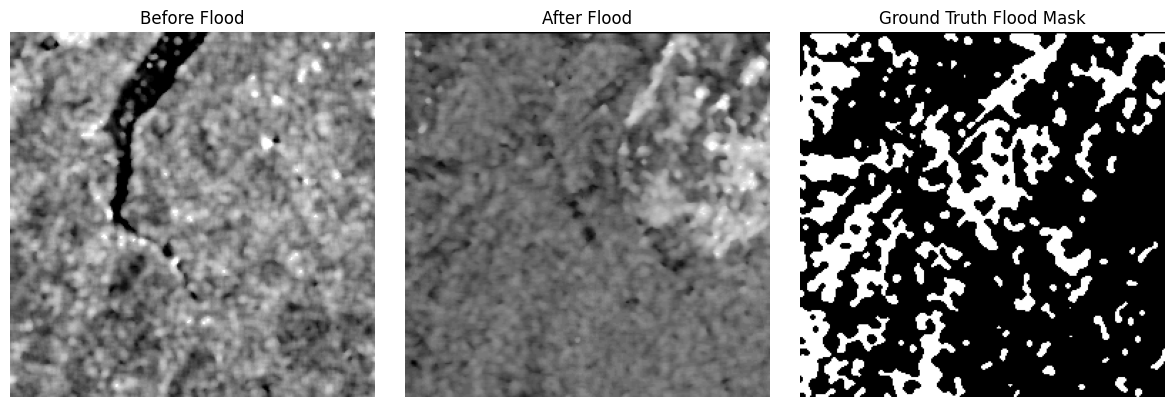

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

base_path = "/content/S1GFloods/S1GFloods"

before = Image.open(os.path.join(base_path, "A", "image_1.png"))
after = Image.open(os.path.join(base_path, "B", "image_1.png"))
mask = Image.open(os.path.join(base_path, "Label", "image_1.png"))

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(before)
plt.title("Before Flood")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(after)
plt.title("After Flood")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Flood Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'S1GFloods', 'sample_data']


In [ ]:
!pip install -q huggingface_hub

from huggingface_hub import hf_hub_download

archive_path = hf_hub_download(
    repo_id="Tamer-Saleh/S1GFloods",
    filename="S1GFloods.rar",
    repo_type="dataset"
)

print("Archive downloaded to:", archive_path)

Archive downloaded to: /root/.cache/huggingface/hub/datasets--Tamer-Saleh--S1GFloods/snapshots/fb4dbe460e97691756d6ef02cfa4695e15232920/S1GFloods.rar


In [ ]:
!apt-get install -y -qq unar

import os

extract_path = "/content/S1GFloods"
os.makedirs(extract_path, exist_ok=True)

!unar -f -o /content/S1GFloods "{archive_path}"

Streaming output truncated to the last 5000 lines.
  B/image_1326.png  (87943 B)... OK.
  B/image_1327.png  (108893 B)... OK.
  B/image_1328.png  (111371 B)... OK.
  B/image_1329.png  (121254 B)... OK.
  B/image_133.png  (116933 B)... OK.
  B/image_1330.png  (116144 B)... OK.
  B/image_1331.png  (103315 B)... OK.
  B/image_1332.png  (118875 B)... OK.
  B/image_1333.png  (109633 B)... OK.
  B/image_1334.png  (114677 B)... OK.
  B/image_1335.png  (108845 B)... OK.
  B/image_1336.png  (104694 B)... OK.
  B/image_1337.png  (103672 B)... OK.
  B/image_1338.png  (106854 B)... OK.
  B/image_1339.png  (107212 B)... OK.
  B/image_134.png  (115324 B)... OK.
  B/image_1340.png  (99673 B)... OK.
  B/image_1341.png  (106578 B)... OK.
  B/image_1342.png  (116306 B)... OK.
  B/image_1343.png  (13885 B)... OK.
  B/image_1344.png  (74826 B)... OK.
  B/image_1345.png  (111898 B)... OK.
  B/image_1346.png  (127534 B)... OK.
  B/image_1347.png  (108924 B)... OK.
  B/image_1348.png  (114235 B)... OK.
  B/i

In [ ]:
import numpy as np
from PIL import Image
import os

mask_path = "/content/S1GFloods/S1GFloods/Label/image_1.png"

mask = np.array(Image.open(mask_path))

values, counts = np.unique(mask, return_counts=True)

for value, count in zip(values, counts):
    print(f"Pixel value {value}: {count} pixels")

Pixel value 0: 47914 pixels
Pixel value 255: 17622 pixels


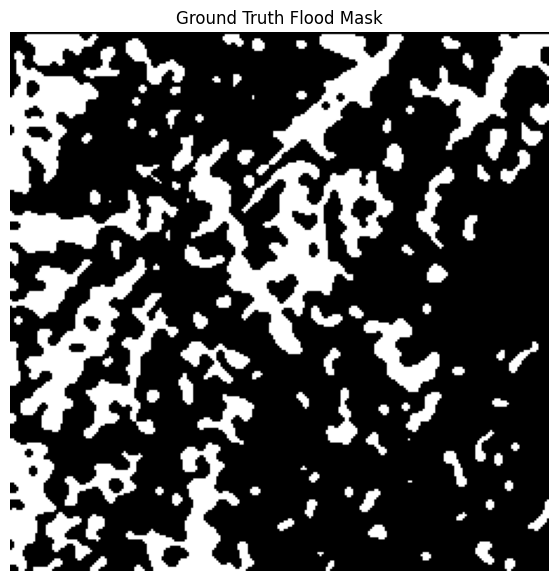

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(7, 7))

plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Flood Mask")
plt.axis("off")

plt.show()

In [ ]:
print("Unique values:", np.unique(mask))
print("Mask shape:", mask.shape)

Unique values: [  0 255]
Mask shape: (256, 256)


In [ ]:
%whos

Variable          Type             Data/Info
--------------------------------------------
HfApi             type             <class 'huggingface_hub.hf_api.HfApi'>
Image             module           <module 'PIL.Image' from <...>t-packages/PIL/Image.py'>
after             PngImageFile     <PIL.PngImagePlugin.PngIm<...>56x256 at 0x7D44B969C180>
api               HfApi            <huggingface_hub.hf_api.H<...>object at 0x7d44ca11b890>
archive_path      str              /root/.cache/huggingface/<...>95e15232920/S1GFloods.rar
base_path         str              /content/S1GFloods/S1GFloods
before            PngImageFile     <PIL.PngImagePlugin.PngIm<...>56x256 at 0x7D44C9026190>
count             int64            17622
counts            ndarray          2: 2 elems, type `int64`, 16 bytes
dataset_info      DatasetInfo      DatasetInfo(id='Tamer-Sal<...>, used_storage=673724972)
extract_path      str              /content/S1GFloods
file              TextIOWrapper    <_io.TextIOWrapper name='<

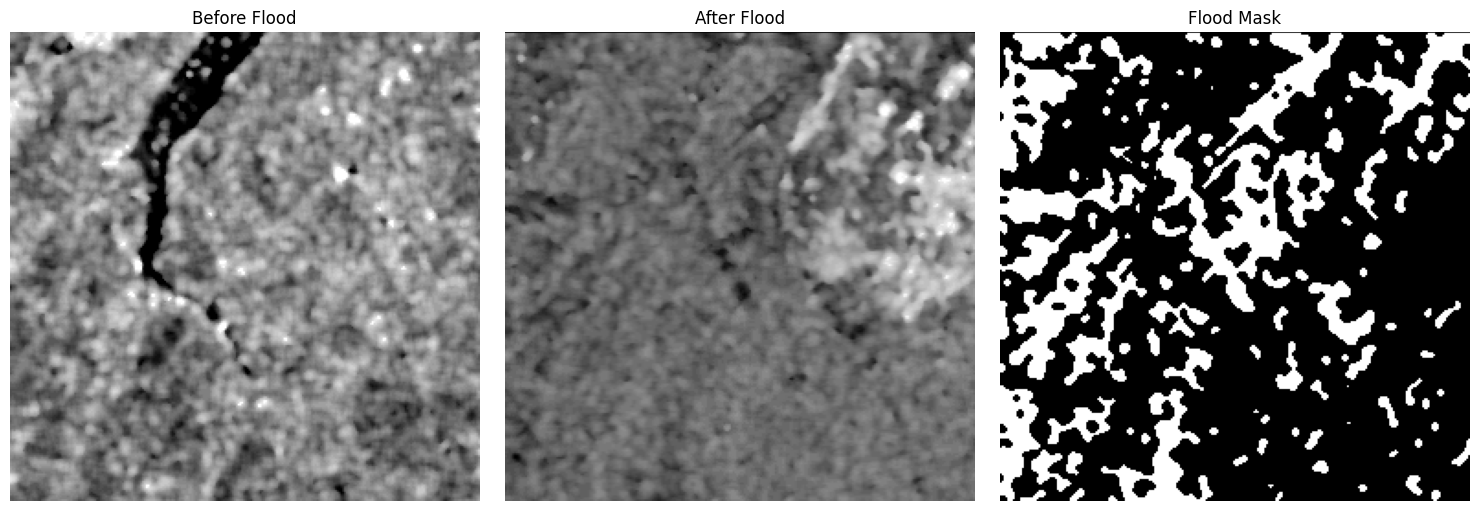

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(before, cmap="gray")
axes[0].set_title("Before Flood")
axes[0].axis("off")

axes[1].imshow(after, cmap="gray")
axes[1].set_title("After Flood")
axes[1].axis("off")

axes[2].imshow(mask, cmap="gray")
axes[2].set_title("Flood Mask")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

for root, dirs, filenames in os.walk(base_path):
    level = root.replace(base_path, '').count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for filename in filenames[:5]:
            print("  " * (level + 1) + filename)

S1GFloods/
  B/
    image_4725.png
    image_3036.png
    image_1984.png
    image_2122.png
    image_3166.png
  Label/
    image_4725.png
    image_3036.png
    image_1984.png
    image_2122.png
    image_3166.png
  A/
    image_4725.png
    image_3036.png
    image_1984.png
    image_2122.png
    image_3166.png


In [ ]:
import os
from PIL import Image
import numpy as np

A_path = os.path.join(base_path, "A")
B_path = os.path.join(base_path, "B")
Label_path = os.path.join(base_path, "Label")

A_files = set(os.listdir(A_path))
B_files = set(os.listdir(B_path))
Label_files = set(os.listdir(Label_path))

common_files = sorted(A_files & B_files & Label_files)

print("Images in A:", len(A_files))
print("Images in B:", len(B_files))
print("Masks in Label:", len(Label_files))
print("Complete matching samples:", len(common_files))

# Inspect one sample
sample = common_files[0]

img_A = Image.open(os.path.join(A_path, sample))
img_B = Image.open(os.path.join(B_path, sample))
img_mask = Image.open(os.path.join(Label_path, sample))

print("\nSample:", sample)
print("A shape:", np.array(img_A).shape)
print("B shape:", np.array(img_B).shape)
print("Mask shape:", np.array(img_mask).shape)
print("Mask values:", np.unique(np.array(img_mask)))

Images in A: 5360
Images in B: 5360
Masks in Label: 5360
Complete matching samples: 5360

Sample: image_1.png
A shape: (256, 256, 3)
B shape: (256, 256, 3)
Mask shape: (256, 256)
Mask values: [  0 255]


In [ ]:
from sklearn.model_selection import train_test_split

train_files, temp_files = train_test_split(
    common_files,
    test_size=0.30,
    random_state=42
)

val_files, test_files = train_test_split(
    temp_files,
    test_size=0.50,
    random_state=42
)

print("Training samples:", len(train_files))
print("Validation samples:", len(val_files))
print("Testing samples:", len(test_files))

Training samples: 3752
Validation samples: 804
Testing samples: 804


In [ ]:
import tensorflow as tf
import os

def load_sample(filename):

    path_A = tf.strings.join([A_path, "/", filename])
    path_B = tf.strings.join([B_path, "/", filename])
    path_mask = tf.strings.join([Label_path, "/", filename])

    # Load before and after images
    image_A = tf.io.decode_png(
        tf.io.read_file(path_A), channels=3
    )

    image_B = tf.io.decode_png(
        tf.io.read_file(path_B), channels=3
    )

    # Normalize images to 0-1
    image_A = tf.cast(image_A, tf.float32) / 255.0
    image_B = tf.cast(image_B, tf.float32) / 255.0

    # Combine both images into six channels
    combined_image = tf.concat([image_A, image_B], axis=-1)

    # Load and convert mask to binary 0/1
    mask = tf.io.decode_png(
        tf.io.read_file(path_mask), channels=1
    )

    mask = tf.cast(mask > 0, tf.float32)

    return combined_image, mask


def create_dataset(files, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(files)

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(files),
            seed=42
        )

    dataset = dataset.map(
        load_sample,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(8)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_dataset = create_dataset(train_files, training=True)
val_dataset = create_dataset(val_files)
test_dataset = create_dataset(test_files)

In [ ]:
import os

folders = {
    "A": A_path,
    "B": B_path,
    "Label": Label_path
}

empty_files = []

for folder_name, folder in folders.items():
    for filename in common_files:
        filepath = os.path.join(folder, filename)

        if os.path.getsize(filepath) == 0:
            empty_files.append((folder_name, filename))

print("Empty files found:", len(empty_files))

for item in empty_files[:20]:
    print(item)

Empty files found: 450
('A', 'image_1527.png')
('A', 'image_1758.png')
('A', 'image_1788.png')
('A', 'image_1791.png')
('A', 'image_1797.png')
('A', 'image_1802.png')
('A', 'image_1806.png')
('A', 'image_1976.png')
('A', 'image_2013.png')
('A', 'image_2100.png')
('A', 'image_2487.png')
('A', 'image_2495.png')
('A', 'image_2738.png')
('A', 'image_2911.png')
('A', 'image_3575.png')
('A', 'image_3594.png')
('A', 'image_3638.png')
('A', 'image_378.png')
('A', 'image_3942.png')
('A', 'image_3976.png')


In [ ]:
import os
from PIL import Image

valid_files = []
invalid_files = []

for filename in common_files:

    paths = [
        os.path.join(A_path, filename),
        os.path.join(B_path, filename),
        os.path.join(Label_path, filename)
    ]

    is_valid = True

    for filepath in paths:
        try:
            if os.path.getsize(filepath) == 0:
                is_valid = False
                break

            with Image.open(filepath) as im:
                im.verify()

        except Exception:
            is_valid = False
            break

    if is_valid:
        valid_files.append(filename)
    else:
        invalid_files.append(filename)

print("Original samples:", len(common_files))
print("Valid samples:", len(valid_files))
print("Invalid samples:", len(invalid_files))

Original samples: 5360
Valid samples: 4921
Invalid samples: 439


In [ ]:
from sklearn.model_selection import train_test_split

train_files, temp_files = train_test_split(
    valid_files,
    test_size=0.30,
    random_state=42
)

val_files, test_files = train_test_split(
    temp_files,
    test_size=0.50,
    random_state=42
)

print("Training:", len(train_files))
print("Validation:", len(val_files))
print("Testing:", len(test_files))

Training: 3444
Validation: 738
Testing: 739


In [ ]:
train_dataset = create_dataset(train_files, training=True)
val_dataset = create_dataset(val_files)
test_dataset = create_dataset(test_files)

In [ ]:
for images, masks in train_dataset.take(1):

    print("Input batch shape:", images.shape)
    print("Mask batch shape:", masks.shape)

    print("Image minimum:", tf.reduce_min(images).numpy())
    print("Image maximum:", tf.reduce_max(images).numpy())

    print("Mask unique values:", tf.unique(
        tf.reshape(masks, [-1])
    )[0].numpy())

Input batch shape: (8, 256, 256, 6)
Mask batch shape: (8, 256, 256, 1)
Image minimum: 0.0
Image maximum: 1.0
Mask unique values: [0. 1.]


In [ ]:
print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from tensorflow.keras import layers, Model

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    return x


def build_unet():

    inputs = layers.Input((256, 256, 6))

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 256)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    c5 = conv_block(p4, 512)

    # Decoder
    u6 = layers.UpSampling2D()(c5)
    u6 = layers.Concatenate()([u6, c4])
    c6 = conv_block(u6, 256)

    u7 = layers.UpSampling2D()(c6)
    u7 = layers.Concatenate()([u7, c3])
    c7 = conv_block(u7, 128)

    u8 = layers.UpSampling2D()(c7)
    u8 = layers.Concatenate()([u8, c2])
    c8 = conv_block(u8, 64)

    u9 = layers.UpSampling2D()(c8)
    u9 = layers.Concatenate()([u9, c1])
    c9 = conv_block(u9, 32)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid"
    )(c9)

    return Model(inputs, outputs)


model = build_unet()

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │      1,760 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]  

 Total params: 7,859,297 (29.98 MB)

 Trainable params: 7,853,409 (29.96 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [ ]:
def dice_loss(y_true, y_pred):

    smooth = 1e-6

    intersection = tf.reduce_sum(
        y_true * y_pred, axis=[1, 2, 3]
    )

    union = tf.reduce_sum(
        y_true + y_pred, axis=[1, 2, 3]
    )

    dice = (2. * intersection + smooth) / (
        union + smooth
    )

    return 1 - tf.reduce_mean(dice)


def combined_loss(y_true, y_pred):

    bce = tf.keras.losses.binary_crossentropy(
        y_true, y_pred
    )

    return tf.reduce_mean(bce) + dice_loss(
        y_true, y_pred
    )


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=combined_loss,
    metrics=[
        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="flood_IoU"
        ),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("U-Net model compiled successfully!")

U-Net model compiled successfully!


In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_flood_unet.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Training callbacks configured!")

Training callbacks configured!


In [ ]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30
431/431 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - flood_IoU: 0.7533 - loss: 0.5825 - precision: 0.8337 - recall: 0.8829
Epoch 1: val_loss improved from None to 0.37694, saving model to best_flood_unet.keras

Epoch 1: finished saving model to best_flood_unet.keras
431/431 ━━━━━━━━━━━━━━━━━━━━ 193s 328ms/step - flood_IoU: 0.8028 - loss: 0.4772 - precision: 0.8661 - recall: 0.9166 - val_flood_IoU: 0.8537 - val_loss: 0.3769 - val_precision: 0.8993 - val_recall: 0.9439 - learning_rate: 1.0000e-04
Epoch 2/30
431/431 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - flood_IoU: 0.8433 - loss: 0.3750 - precision: 0.8949 - recall: 0.9361
Epoch 2: val_loss improved from 0.37694 to 0.28463, saving model to best_flood_unet.keras

Epoch 2: finished saving model to best_flood_unet.keras
431/431 ━━━━━━━━━━━━━━━━━━━━ 108s 251ms/step - flood_IoU: 0.8498 - loss: 0.3552 - precision: 0.9011 - recall: 0.9373 - val_flood_IoU: 0.8856 - val_loss: 0.2846 - val_precision: 0.9396 - val_recall: 0.9391 - learning_rate: 1.

In [ ]:
import matplotlib.pyplot as plt

print("Best validation loss:",
      min(history.history["val_loss"]))

print("Best training loss:",
      min(history.history["loss"]))

print("Best validation IoU:",
      max(history.history["val_flood_IoU"]))

print("Best validation precision:",
      max(history.history["val_precision"]))

print("Best validation recall:",
      max(history.history["val_recall"]))

Best validation loss: 0.1587572991847992
Best training loss: 0.13141588866710663
Best validation IoU: 0.9248330593109131
Best validation precision: 0.9648342132568359
Best validation recall: 0.9736855626106262


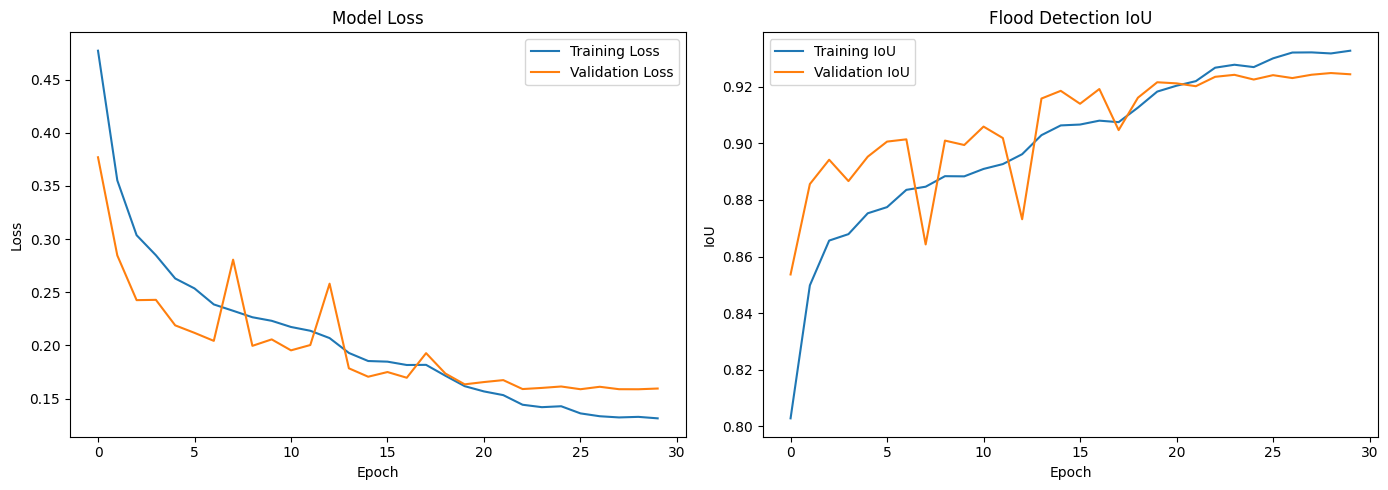

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Model Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# IoU
axes[1].plot(history.history["flood_IoU"], label="Training IoU")
axes[1].plot(history.history["val_flood_IoU"], label="Validation IoU")
axes[1].set_title("Flood Detection IoU")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("IoU")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
test_results = model.evaluate(
    test_dataset,
    return_dict=True,
    verbose=1
)

print("\nFINAL TEST RESULTS")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

93/93 ━━━━━━━━━━━━━━━━━━━━ 11s 115ms/step - flood_IoU: 0.9241 - loss: 0.1667 - precision: 0.9589 - recall: 0.9622

FINAL TEST RESULTS
flood_IoU: 0.9241
loss: 0.1667
precision: 0.9589
recall: 0.9622


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


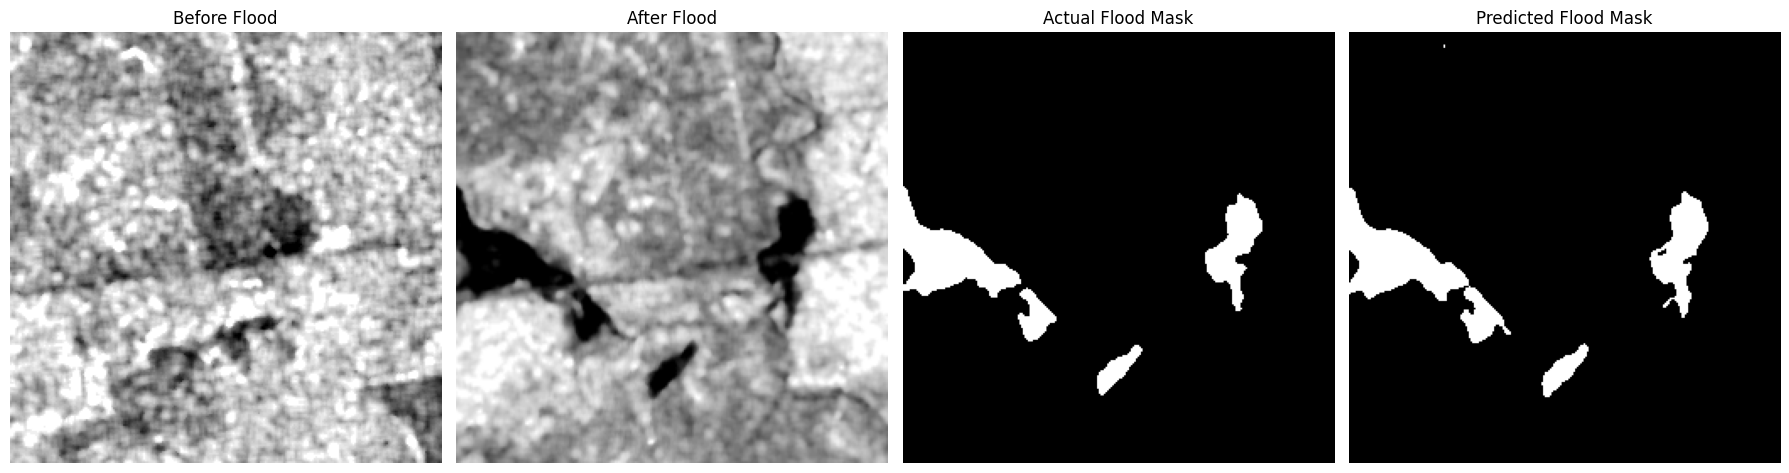

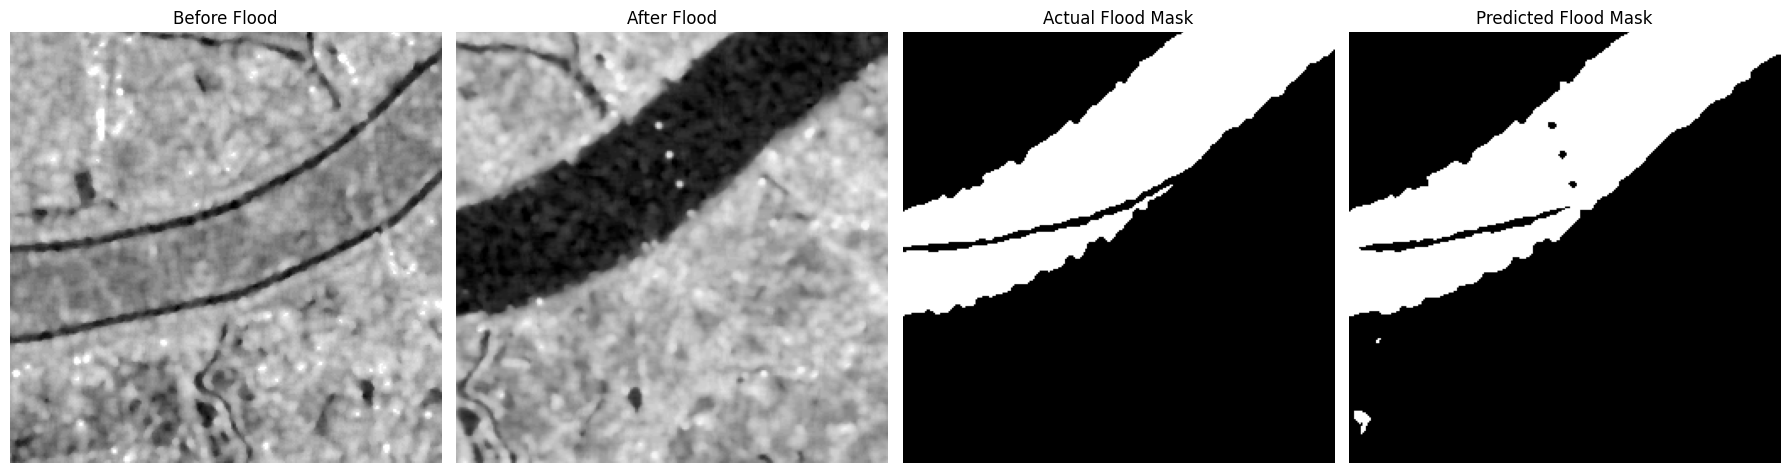

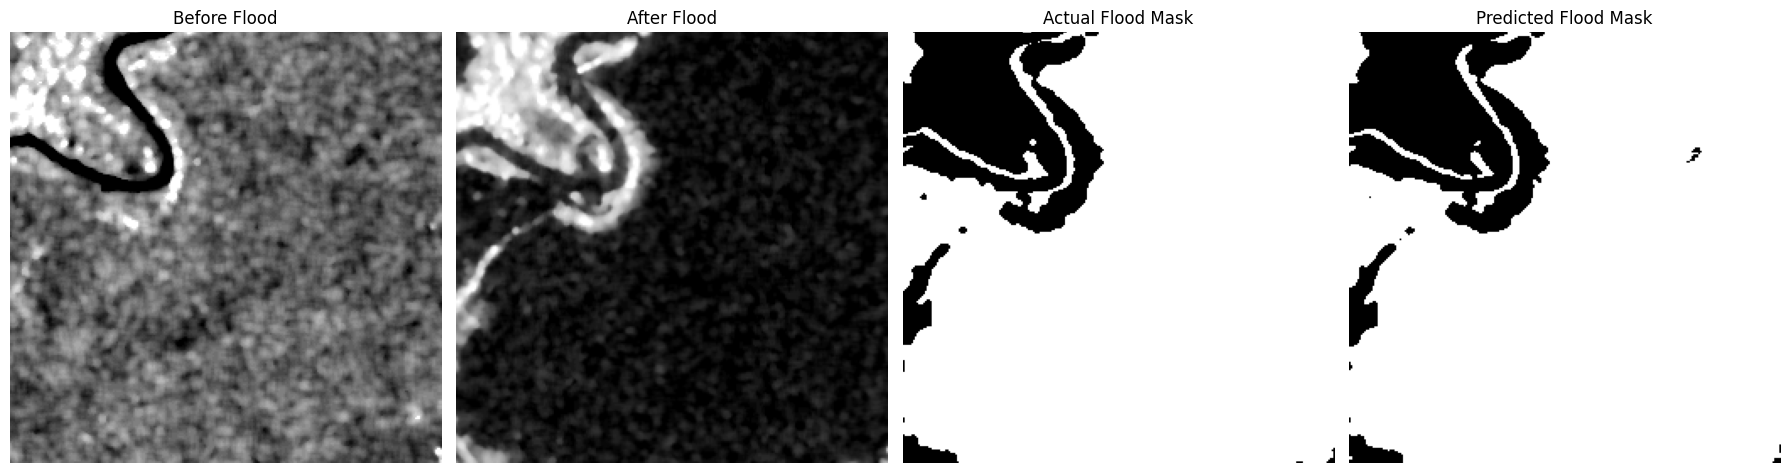

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

for images, masks in test_dataset.take(1):

    predictions = model.predict(images)

    for i in range(3):

        before_img = images[i, :, :, :3].numpy()
        after_img = images[i, :, :, 3:6].numpy()

        actual_mask = masks[i, :, :, 0].numpy()
        predicted_mask = (predictions[i, :, :, 0] > 0.5).astype(np.uint8)

        fig, axes = plt.subplots(1, 4, figsize=(18, 5))

        axes[0].imshow(before_img)
        axes[0].set_title("Before Flood")

        axes[1].imshow(after_img)
        axes[1].set_title("After Flood")

        axes[2].imshow(actual_mask, cmap="gray")
        axes[2].set_title("Actual Flood Mask")

        axes[3].imshow(predicted_mask, cmap="gray")
        axes[3].set_title("Predicted Flood Mask")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

In [ ]:
test_results = model.evaluate(
    test_dataset,
    return_dict=True,
    verbose=1
)

print("\n===== FINAL TEST RESULTS =====")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

93/93 ━━━━━━━━━━━━━━━━━━━━ 7s 78ms/step - flood_IoU: 0.9241 - loss: 0.1667 - precision: 0.9589 - recall: 0.9622

===== FINAL TEST RESULTS =====
flood_IoU: 0.9241
loss: 0.1667
precision: 0.9589
recall: 0.9622


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step


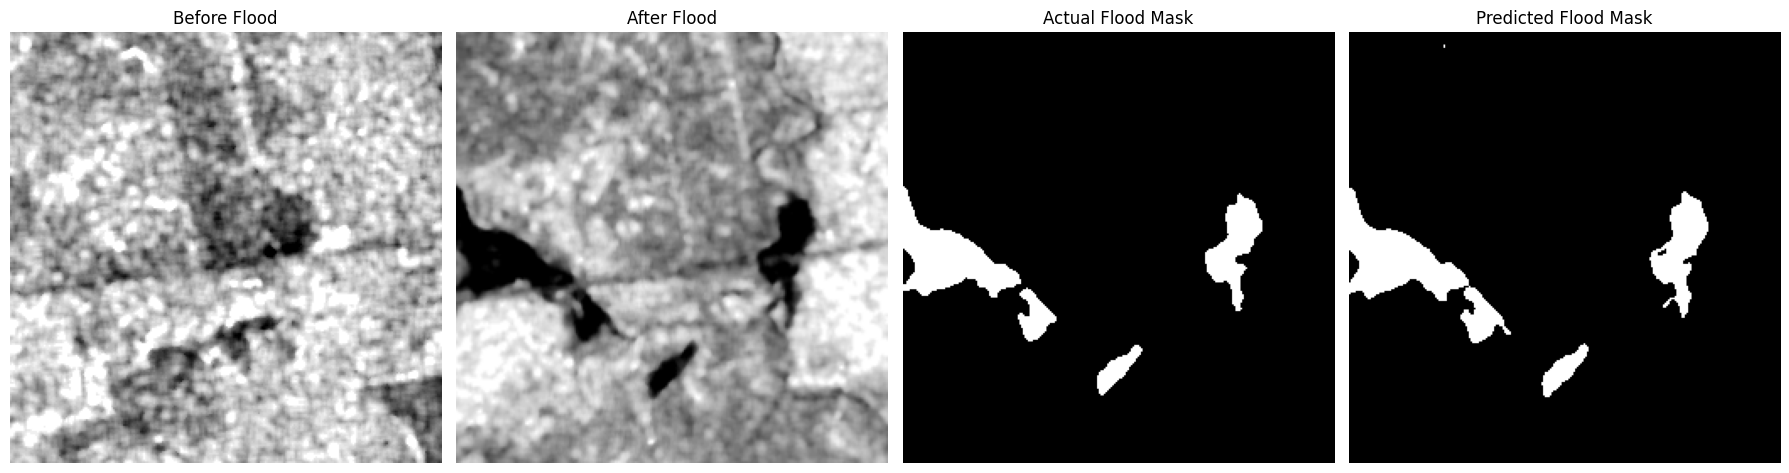

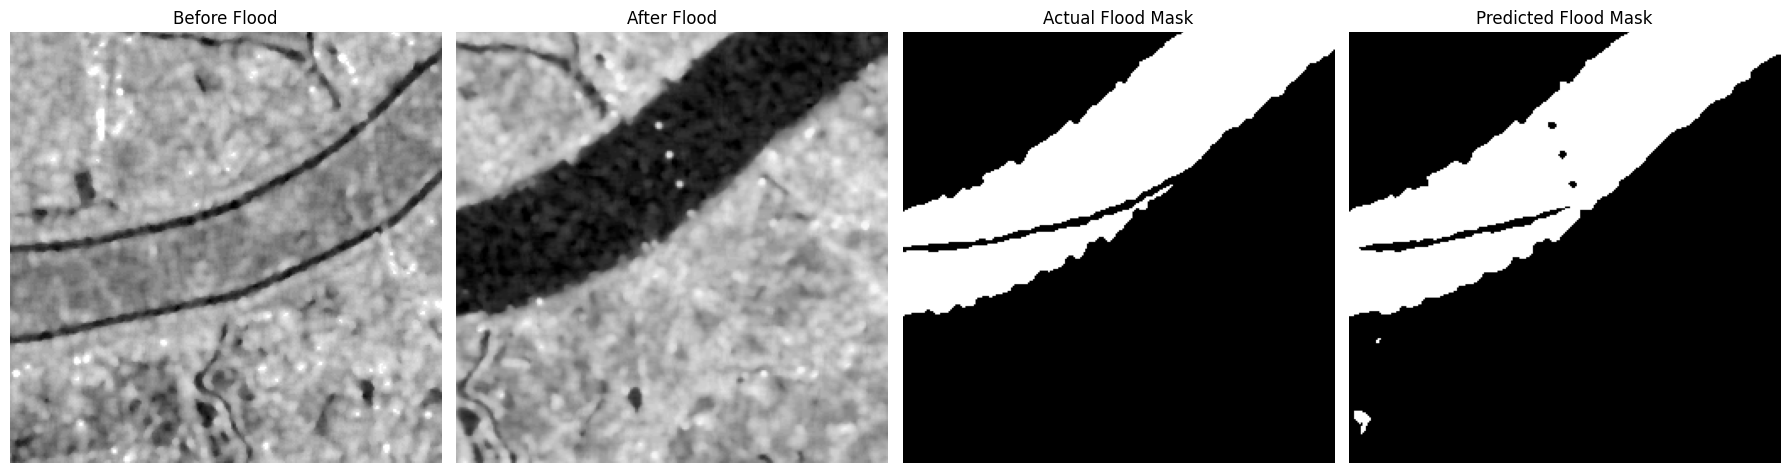

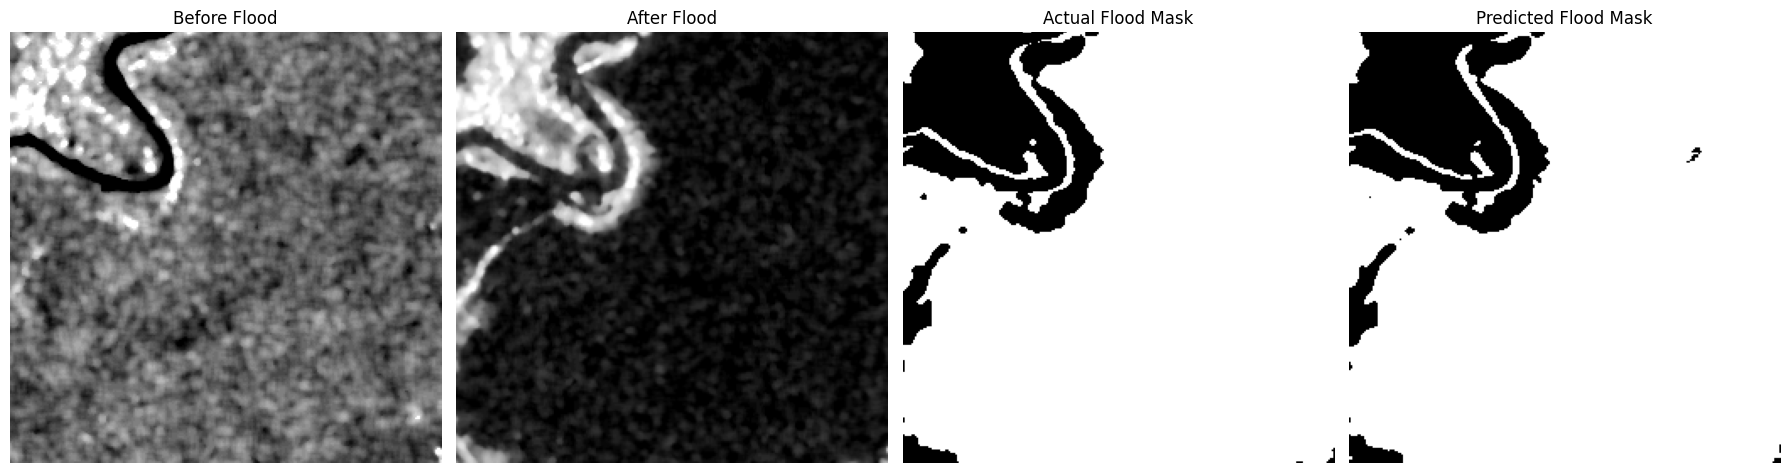

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

for images, masks in test_dataset.take(1):
    predictions = model.predict(images)

    for i in range(3):
        before_img = images[i, :, :, :3].numpy()
        after_img = images[i, :, :, 3:6].numpy()

        actual_mask = masks[i, :, :, 0].numpy()
        predicted_mask = (
            predictions[i, :, :, 0] > 0.5
        ).astype(np.uint8)

        fig, axes = plt.subplots(1, 4, figsize=(18, 5))

        axes[0].imshow(before_img)
        axes[0].set_title("Before Flood")

        axes[1].imshow(after_img)
        axes[1].set_title("After Flood")

        axes[2].imshow(actual_mask, cmap="gray")
        axes[2].set_title("Actual Flood Mask")

        axes[3].imshow(predicted_mask, cmap="gray")
        axes[3].set_title("Predicted Flood Mask")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

In [ ]:
model.save("/content/flood_unet_final.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("/content/flood_unet_final.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>